# Online Shoppers Purchasing Intention

**Dataset:** UCI Online Shoppers — 12,330 real e-commerce sessions (one row per visit), labelled by whether the visit ended in a purchase (`Revenue`). Only ~15.5% of sessions convert, so — like the fraud project — the interesting question is catching buyers, not raw accuracy.

In [1]:
import io, urllib.request, zipfile
import pandas as pd

def get(url):
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req, timeout=90) as r: return r.read()

zf = zipfile.ZipFile(io.BytesIO(get('https://archive.ics.uci.edu/static/public/468/online+shoppers+purchasing+intention+dataset.zip')))
name = [n for n in zf.namelist() if n.endswith('.csv')][0]
d = pd.read_csv(io.BytesIO(zf.read(name)))
print(d.shape, '| purchase share:', round(100 * d['Revenue'].mean(), 1), '%')
d.head()

(12330, 18) | purchase share: 15.5 %


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


Always-no-purchase baseline: 0.8453
Random Forest accuracy: 0.8994
Logistic Regression accuracy: 0.8563
              precision    recall  f1-score   support

 No purchase       0.92      0.97      0.94      2606
    Purchase       0.74      0.53      0.62       477

    accuracy                           0.90      3083
   macro avg       0.83      0.75      0.78      3083
weighted avg       0.89      0.90      0.89      3083



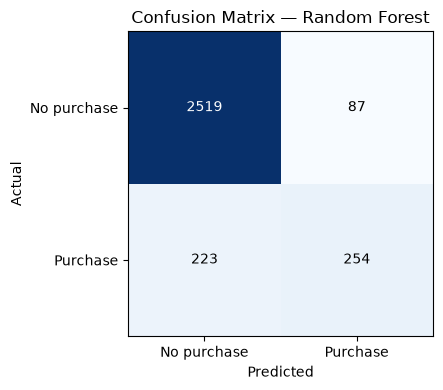

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt

y = d['Revenue'].astype(int)
X = pd.get_dummies(d.drop(columns=['Revenue']), columns=['Month', 'VisitorType', 'Weekend'], drop_first=True)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1).fit(Xtr, ytr)
sc = StandardScaler().fit(Xtr)
lr = LogisticRegression(max_iter=1000, class_weight='balanced').fit(sc.transform(Xtr), ytr)
pred = rf.predict(Xte)
print('Always-no-purchase baseline:', round(float((yte == 0).mean()), 4))
print('Random Forest accuracy:', round(accuracy_score(yte, pred), 4))
print('Logistic Regression accuracy:', round(accuracy_score(yte, lr.predict(sc.transform(Xte))), 4))
print(classification_report(yte, pred, target_names=['No purchase', 'Purchase']))
cm = confusion_matrix(yte, pred)
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(cm, cmap='Blues')
ax.set_xticks([0, 1], ['No purchase', 'Purchase']); ax.set_yticks([0, 1], ['No purchase', 'Purchase'])
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title('Confusion Matrix — Random Forest')
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max()/2 else 'black')
fig.tight_layout(); fig.savefig('confusion_matrix.png', dpi=110); plt.show()

## What I learned
- PageValues (the monetary value Google Analytics assigns a page) dominates — sessions that reach high-value pages convert.
- The accuracy number flatters: a model that never predicts a purchase still scores ~84.5%. Recall on buyers is the metric a shop owner actually cares about.
- Exit/bounce rates and product-page dwell time carry the behavioural signal.